<a href="https://colab.research.google.com/github/kokilahemachandra-afk/srilanka-ntl-midterm/blob/main/notebooks/01_download_ntl_gee.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · Monthly night-time lights for Sri Lanka's DS divisions

Downloads monthly VIIRS night-time lights (NOAA/VIIRS/DNB/MONTHLY_V1/VCMSLCFG)
from Google Earth Engine for Sri Lanka's 330 Divisional Secretariat divisions.

**Goal:** get the monthly night-time light of each of Sri Lanka's 339
Divisional Secretariat (DS) divisions, from January 2014 to the latest month.

**Why night-time lights?** Satellites photograph the Earth at night. Brighter
places usually have more people, electricity and economic activity, so light
is a common stand-in for local economic activity where GDP is not measured.

**Output:** `data/processed/lka_ds339_ntl_monthly.csv`, one row per DS division and month.

### Step 1: connect to Earth Engine.
https://code.earthengine.google.com

Google Earth Engine stores satellite images and does the calculations on
Google's computers, so we never download the large image files.
These cells install the library, log in, and connect to our Cloud project.

Create a new Project in Google Earth Engine "`sri-lanka-ntl-rd-mid`"

In [1]:
# Install the Earth Engine library
!pip install -q earthengine-api

In [5]:
import ee

PROJECT = "sri-lanka-ntl-rd-mid"

ee.Authenticate()              # opens a Google sign-in; allow access
ee.Initialize(project=PROJECT)

print(ee.String("Connected to Earth Engine").getInfo())

Connected to Earth Engine


**A first look at the data**

**VIIRS monthly night-time lights** (`NOAA/VIIRS/DNB/MONTHLY_V1/VCMSLCFG`) is used.
Each image is one month. It has two bands:
- `avg_rad`: how bright each place is at night (radiance)
- `cf_cvg`: how many cloud-free nights were used that month (data quality)

In [6]:
col = ee.ImageCollection("NOAA/VIIRS/DNB/MONTHLY_V1/VCMSLCFG")

print("Number of monthly images:", col.size().getInfo())
first = ee.Date(col.first().get("system:time_start")).format("YYYY-MM").getInfo()
last  = ee.Date(col.sort("system:time_start", False).first().get("system:time_start")).format("YYYY-MM").getInfo()
print("From", first, "to", last)
print("Bands:", col.first().bandNames().getInfo())

Number of monthly images: 153
From 2014-01 to 2026-09
Bands: ['avg_rad', 'cf_cvg']


### Step 2: DS-division boundaries

Create a map of the DS divisions to know which pixels belong to which division.
Source: Survey Department of Sri Lanka, via OCHA COD-AB on HDX
(lka_adm_20220816), licence CC BY-IGO. The file is stored in `data/boundaries/`.

In [9]:
import geopandas as gpd

REPO = "https://raw.githubusercontent.com/kokilahemachandra-afk/srilanka-ntl-midterm/main/"
NAME = "lka_admin3.shp"          # <-- your adm3 file name, without .shp

ds = gpd.read_file(REPO + "data/boundaries/" + NAME)

print("Rows (DS divisions):", len(ds))
print("Columns:", list(ds.columns))
print("Coordinate system:", ds.crs)
ds.drop(columns="geometry").head()

Rows (DS divisions): 339
Columns: ['adm3_name', 'adm3_name1', 'adm3_name2', 'adm3_name3', 'adm3_pcode', 'adm2_name', 'adm2_name1', 'adm2_name2', 'adm2_name3', 'adm2_pcode', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'center_lat', 'center_lon', 'geometry']
Coordinate system: EPSG:4326


,adm3_name,adm3_name1,adm3_name2,adm3_name3,adm3_pcode,adm2_name,adm2_name1,adm2_name2,adm2_name3,adm2_pcode,...,valid_on,valid_to,area_sqkm,version,lang,lang1,lang2,lang3,center_lat,center_lon
0,Colombo,කොළඹ,கொழும்பு,None,LK1103,Colombo,කොළඹ දිස්ත්‍රික්ක,கொழும்பு மாவட்டம்,None,LK11,...,2022-08-16,NaT,24.537151,v03,en,si,ta,None,6.946987,79.865263
1,Kolonnawa,කොලොන්නාව,கொலன்னாவை,None,LK1106,Colombo,කොළඹ දිස්ත්‍රික්ක,கொழும்பு மாவட்டம்,None,LK11,...,2022-08-16,NaT,25.928037,v03,en,si,ta,None,6.934943,79.914709
2,Kaduwela,කඩුවෙල,கடுவெலை,None,LK1109,Colombo,කොළඹ දිස්ත්‍රික්ක,கொழும்பு மாவட்டம்,None,LK11,...,2022-08-16,NaT,86.737826,v03,en,si,ta,None,6.901985,79.972773
3,Homagama,හෝමාගම,கோமகமை,None,LK1112,Colombo,කොළඹ දිස්ත්‍රික්ක,கொழும்பு மாவட்டம்,None,LK11,...,2022-08-16,NaT,120.316227,v03,en,si,ta,None,6.836353,80.024442
4,Seethawaka,සීතාවක,சீதவாக்கை,None,LK1115,Colombo,කොළඹ දිස්ත්‍රික්ක,கொழும்பு மாவட்டம்,None,LK11,...,2022-08-16,NaT,145.976978,v03,en,si,ta,None,6.919902,80.152703


**Checks. Every DS division should appear once, in 25 districts and 9 provinces**

Every DS division should appear once, in 25 districts and 9 provinces, with
valid shapes. We identify divisions by their official code (`adm3_pcode`),
not by name.

In [10]:
print("Unique DS codes:", ds["adm3_pcode"].nunique(), "of", len(ds))
print("Districts:", ds["adm2_name"].nunique(), "| Provinces:", ds["adm1_name"].nunique())
print("Invalid shapes:", (~ds.is_valid).sum())

# DS names that appear in more than one district (why we use codes, not names)
dup = ds[ds["adm3_name"].duplicated(keep=False)]
print("Repeated names:", dup["adm3_name"].nunique())
dup[["adm3_name", "adm2_name", "adm3_pcode"]].sort_values("adm3_name")

Unique DS codes: 339 of 339
Districts: 25 | Provinces: 9
Invalid shapes: 0
Repeated names: 0


,adm3_name,adm2_name,adm3_pcode


**Keep the useful columns and make a lighter copy for Earth Engine.**

Tidy and simplify
- Keep only the codes, English names, district, province and area.
- Rename the code to `geo_id`, the name used by the geo4bolivia functions.
- Make a lighter copy of the shapes (detail under 100 m removed) for Earth
  Engine. The light pixels are about 460 m wide, so nothing important is lost.

Simplified GeoJSON: 1.8 MB


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

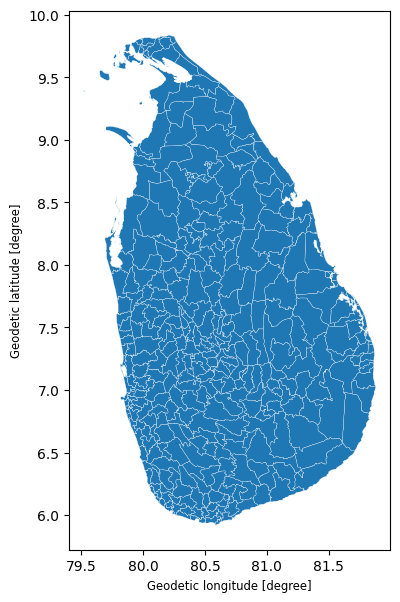

In [11]:
# Keep English names and codes only; geo_id = the official P-code
ds = ds.rename(columns={"adm3_pcode": "geo_id", "adm3_name": "name",
                        "adm2_name": "district", "adm2_pcode": "district_id",
                        "adm1_name": "province", "adm1_pcode": "province_id"})
ds = ds[["geo_id", "name", "district", "district_id", "province", "province_id",
         "area_sqkm", "geometry"]]
ds["geometry"] = ds.make_valid()

# Simplify: remove detail smaller than 100 m (lights pixels are ~460 m, so nothing is lost)
ds_simple = ds.copy()
ds_simple["geometry"] = ds.to_crs(5235).simplify(100).to_crs(4326)

ds_simple.to_file("lka_ds339_simplified.geojson", driver="GeoJSON")
ds.drop(columns="geometry").to_csv("ds_units.csv", index=False)

import os
print("Simplified GeoJSON:", round(os.path.getsize("lka_ds339_simplified.geojson") / 1e6, 1), "MB")
ds_simple.plot(figsize=(5, 7), edgecolor="white", linewidth=0.2)

**Send the boundaries to Earth Engine**

Upload the 339 simplified shapes so Earth Engine can measure the light inside each one.

In [12]:
import json
fc = ee.FeatureCollection(json.loads(ds_simple[["geo_id", "geometry"]].to_json()))
print("Features in Earth Engine:", fc.size().getInfo())

Features in Earth Engine: 339


### Step 3: Monthly night-time lights per DS division
For each month: total light (sum of radiance over the division), average light
(mean radiance), and the average number of cloud-free nights (data quality).

Measure the light in each DS division, every month
For each month and each DS division we compute:
- `avg_rad_sum`: **total light** in the division (main variable)
- `avg_rad_mean`: **average brightness** per pixel
- `cf_cvg_mean`: average number of **cloud-free nights** (quality check)

Small negative values are sensor noise and are set to zero.

In [14]:
col = ee.ImageCollection("NOAA/VIIRS/DNB/MONTHLY_V1/VCMSLCFG").select(["avg_rad", "cf_cvg"])

# For each DS division: the sum and the mean of each band
reducer = ee.Reducer.sum().combine(ee.Reducer.mean(), sharedInputs=True)

def measure(img):
    # Tiny negative radiance values are sensor noise: set them to 0
    img = img.addBands(img.select("avg_rad").max(0), overwrite=True)
    date = ee.Date(img.get("system:time_start"))
    out = img.reduceRegions(collection=fc, reducer=reducer,
                            scale=463.83,   # VIIRS pixel size in metres
                            tileScale=4)    # splits the work so it doesn't run out of memory
    return out.map(lambda f: f.set({"year": date.get("year"), "month": date.get("month")}))

**Check - test on January 2023, first 5 divisions.**

Before running everything, test on January 2023 and five divisions to check
that the numbers look sensible.

In [15]:
import pandas as pd
jan = col.filterDate("2023-01-01", "2023-02-01").first()
test = measure(jan).limit(5).getInfo()

pd.DataFrame([f["properties"] for f in test["features"]])[
    ["geo_id", "year", "month", "avg_rad_sum", "avg_rad_mean", "cf_cvg_mean"]]

,geo_id,year,month,avg_rad_sum,avg_rad_mean,cf_cvg_mean
0,LK1103,2023,1,3339.176550,29.058118,3.365901
1,LK1106,2023,1,1081.296664,8.882217,2.831137
2,LK1109,2023,1,2315.020827,5.671509,2.706851
3,LK1112,2023,1,1705.864431,3.011787,2.897377
4,LK1115,2023,1,700.861645,1.020276,2.203456


**Extract and Upload NTL data to Google drive**

Run all months and save to Google Drive

153 months × 339 divisions is too much to send straight back to Colab, so
Earth Engine runs it as a background task and saves the CSV in Google Drive
(folder `earthengine`). This takes about 10–30 minutes.

In [19]:
table = col.map(measure).flatten()

task = ee.batch.Export.table.toDrive(
    collection=table,
    description="lka_ds339_ntl_monthly",
    folder="earthengine",
    fileNamePrefix="lka_ds339_ntl_monthly",
    fileFormat="CSV",
    selectors=["geo_id", "year", "month", "avg_rad_sum", "avg_rad_mean", "cf_cvg_mean"])
task.start()
print("Started. Number of months:", col.size().getInfo())

Started. Number of months: 153


**Check progress**

Rerun this cell until it says `COMPLETED`.

In [24]:
task.status()["state"]     # READY → RUNNING → COMPLETED

'COMPLETED'

### Result
`lka_ds339_ntl_monthly.csv`: **51,867 rows** (339 divisions × 153 months,
January 2014 to September 2026), with no missing values.

Notes for the next notebook:
- In cloudy monsoon months (mainly July–August) some divisions have fewer than
  one cloud-free night and their light drops to near zero. These months must be
  flagged before analysis.
- 2026 is incomplete, so yearly averages use 2014–2025.

The file was copied to `data/processed/` in this repository.
Next: `02_build_panel.ipynb`.